# Blockpose — Point-Cloud Block Detector Showcase

**Python-first prototype track.** 6-DoF pose estimation of concrete blocks
(0.6 × 0.6 × 0.9 m) from LiDAR point clouds:

1. **Synthetic scene generation** — Open3D raycasting of an enriched environment
   (blocks in the working area; **trees, a shipping container, and wood logs on the
   sides**) → partial-visibility clouds with *exact* ground truth.
2. **The detector** — plane-based `DetectFree`: voxel downsample → ground removal →
   clustering → per-cluster plane fit → closed-form pose.
3. **Symmetry-aware evaluation** — Hungarian matching + 4-fold-symmetry rotation error.
4. **The regression gate** — the machine-checkable Phase-A acceptance metric.

> Blocks are full **6-DoF** (they tilt a few degrees on uneven ground); gravity is a
> *prior*, not a constraint. Clutter adds returns/occlusion but no ground truth, so it
> stresses detector **precision** (false positives). See `docs/detector-plan.md`.


In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "python"))
sys.path.insert(0, str(REPO_ROOT / "tools"))

from blockpose.synth import (
    BlockSpec, SynthParams, ClutterParams, generate_scene, random_scene,
)
from blockpose.detection import DetectionParams, detect_blocks
from blockpose.evaluate import evaluate
print("imports ok")


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


imports ok


## Plotting helpers

Matplotlib 3D rendering so the notebook renders inline anywhere (no GUI window).
Two views per case:

- **`show_full_scene`** — the whole scene (blocks + side clutter), ground-truth boxes drawn
  so you can locate the blocks among the trees/container/logs.
- **`show_scene`** — a focused zoom on the working area, overlaying detected boxes (blue) on
  ground truth (green).


In [2]:
def _box_edges(center, R, dims):
    """12 edges of a posed cuboid -> list of (2,3) segments in world frame."""
    dims = np.asarray(dims, float)
    signs = np.array([[sx, sy, sz] for sx in (-1, 1) for sy in (-1, 1) for sz in (-1, 1)])
    corners = (R @ (signs * dims / 2.0).T).T + np.asarray(center, float)
    edges = [(i, j) for i in range(8) for j in range(i + 1, 8) if bin(i ^ j).count("1") == 1]
    return [np.stack([corners[i], corners[j]]) for i, j in edges]


def _draw_boxes(ax, poses, color, label, lw=2.6):
    first = True
    for p in poses:
        for seg in _box_edges(p.position, p.rotation, (0.6, 0.6, 0.9)):
            ax.plot(*seg.T, color=color, lw=lw, label=label if first else None, zorder=5)
            first = False


def _center(pts, gt, det):
    refs = [p.position for p in (gt or [])] + [p.position for p in (det or [])]
    return np.mean(refs, axis=0) if refs else pts.mean(0)


def show_full_scene(pts, gt=None, title="", reach=7.0, elev=34, azim=-72, subsample=22000):
    """Whole scene: blocks + side clutter (trees / container / logs). GT boxes mark the blocks."""
    ctr = _center(pts, gt, None)
    keep = (np.abs(pts[:, 0] - ctr[0]) < reach) & (np.abs(pts[:, 1] - ctr[1]) < reach)
    p = pts[keep]
    if len(p) > subsample:
        p = p[np.random.default_rng(0).choice(len(p), subsample, replace=False)]
    fig = plt.figure(figsize=(10, 6.2))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap="turbo", s=3, alpha=0.6, depthshade=False)
    if gt:
        _draw_boxes(ax, gt, "#00e000", "ground truth", lw=2.0)
    zmax = max(3.6, float(p[:, 2].max()) if len(p) else 3.6)
    ax.set_xlim(ctr[0] - reach, ctr[0] + reach)
    ax.set_ylim(ctr[1] - reach, ctr[1] + reach)
    ax.set_zlim(0, zmax)
    ax.set_box_aspect((2 * reach, 2 * reach, zmax))
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title=title)
    ax.view_init(elev=elev, azim=azim)
    if gt:
        ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


def show_scene(pts, gt=None, det=None, title="", elev=24, azim=-62, margin=0.7, subsample=14000):
    """Focused zoom on the working area: detected boxes (blue) vs ground truth (green)."""
    ctr = _center(pts, gt, det)
    refs = [p.position for p in (gt or [])] + [p.position for p in (det or [])]
    reach = (float(np.abs(np.asarray(refs) - ctr).max()) + 0.55 if refs else 1.5) + margin
    keep = ((np.abs(pts[:, 0] - ctr[0]) < reach) & (np.abs(pts[:, 1] - ctr[1]) < reach) &
            (pts[:, 2] < ctr[2] + reach))
    p = pts[keep]
    if len(p) > subsample:
        p = p[np.random.default_rng(0).choice(len(p), subsample, replace=False)]
    fig = plt.figure(figsize=(8.5, 6.5))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(p[:, 0], p[:, 1], p[:, 2], c=p[:, 2], cmap="turbo", s=8, alpha=0.75, depthshade=False)
    if gt:
        _draw_boxes(ax, gt, "#00e000", "ground truth")
    if det:
        _draw_boxes(ax, det, "#1e78ff", "detected")
    zmax = max(1.0, float(ctr[2] + reach))
    ax.set_xlim(ctr[0] - reach, ctr[0] + reach)
    ax.set_ylim(ctr[1] - reach, ctr[1] + reach)
    ax.set_zlim(0, zmax)
    ax.set_box_aspect((2 * reach, 2 * reach, zmax))
    ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]", title=title)
    ax.view_init(elev=elev, azim=azim)
    _, labels = ax.get_legend_handles_labels()
    if labels:
        ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


def showcase_case(pts, gt, name):
    """Run the detector, print metrics, then render whole-scene + focused views."""
    det = detect_blocks(pts, DetectionParams())
    res = evaluate(det, gt, max_match_dist=0.5)
    fp = len(det) - res.matched
    print(f"{name}\n  blocks={len(gt)}  detected={len(det)}  matched={res.matched}  "
          f"false-positives={fp}  t_err={res.mean_translation_m*1000:.0f} mm  "
          f"r_err={res.mean_rotation_deg:.2f} deg")
    show_full_scene(pts, gt=gt, title=f"{name} — whole scene (blocks + side clutter)")
    show_scene(pts, gt=gt, det=det, title=f"{name} — focused: detected (blue) vs GT (green)")
    return det, res

print("helpers ready")


helpers ready


## The enriched environment

Scenes generated with `ClutterParams()` add **trees on the left and right**, a **shipping
container**, and **wood logs on the floor** — all on the sides, so the central working area
stays free for blocks. We use a wide sensor FOV so the side clutter is in view.


119457 points, 3 blocks; scene y-range [-19.7, 20.3] m


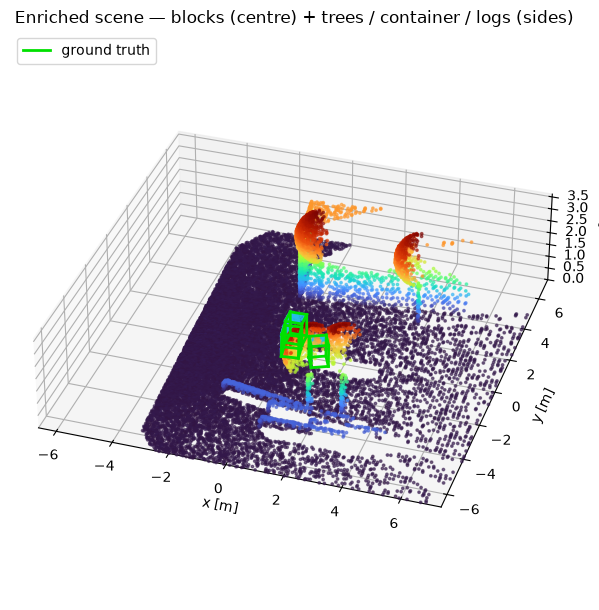

In [3]:
SHOW = SynthParams(az_fov_deg=120.0, el_fov_deg=75.0, range_noise_std=0.01)
CLUTTER = ClutterParams()

pts_env, gt_env = random_scene(3, SHOW, np.random.default_rng(7), spacing=1.0, clutter=CLUTTER)
print(f"{len(pts_env)} points, {len(gt_env)} blocks; scene y-range "
      f"[{pts_env[:,1].min():.1f}, {pts_env[:,1].max():.1f}] m")
show_full_scene(pts_env, gt=gt_env,
                title="Enriched scene — blocks (centre) + trees / container / logs (sides)")


## Test cases

For each case: the **whole scene**, then a **focused view** overlaying the detector output
on ground truth, with metrics (matched / false-positives / translation & rotation error).


### Case 1 — single block in clutter

Case 1: single block in clutter
  blocks=1  detected=1  matched=1  false-positives=0  t_err=90 mm  r_err=0.20 deg


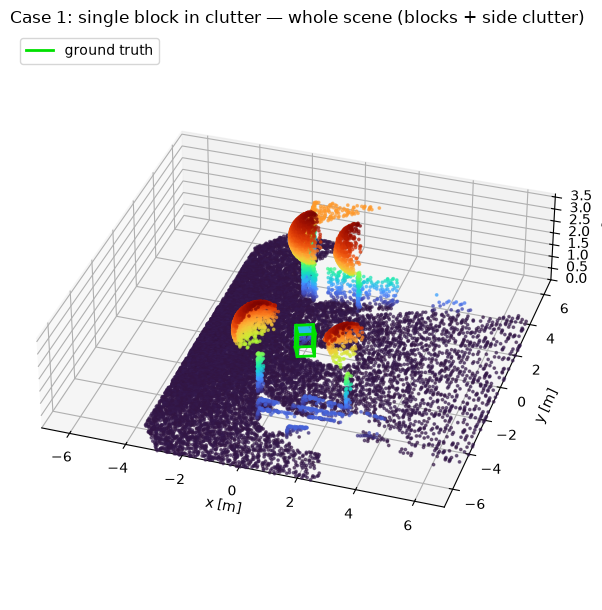

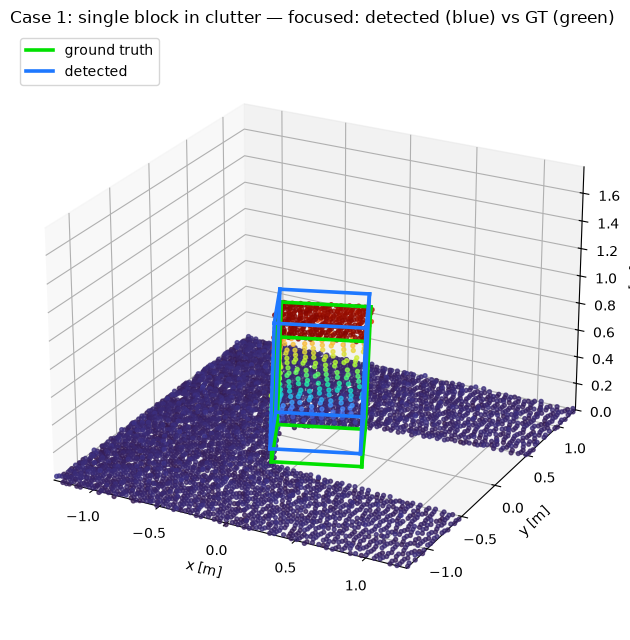

In [4]:
pts1, gt1 = generate_scene(
    [BlockSpec(0.0, 0.0, yaw_deg=25.0, pitch_deg=2.0, roll_deg=-1.5)],
    SHOW, np.random.default_rng(3), clutter=CLUTTER,
)
_ = showcase_case(pts1, gt1, "Case 1: single block in clutter")


### Case 2 — three blocks in clutter

Case 2: three blocks in clutter
  blocks=3  detected=3  matched=3  false-positives=0  t_err=131 mm  r_err=0.45 deg


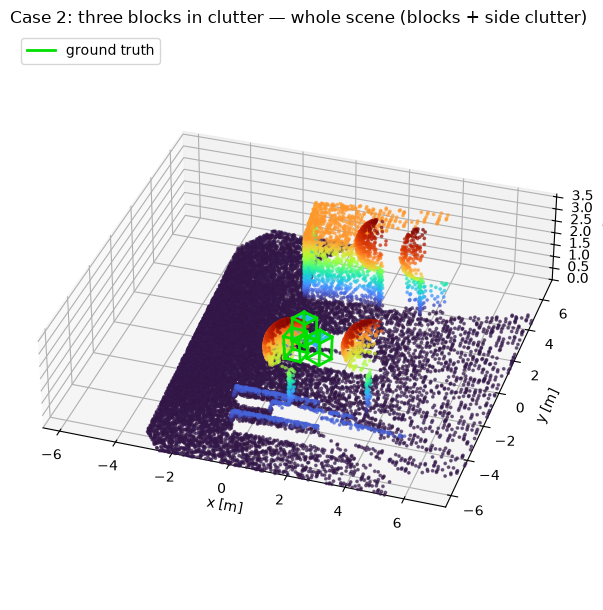

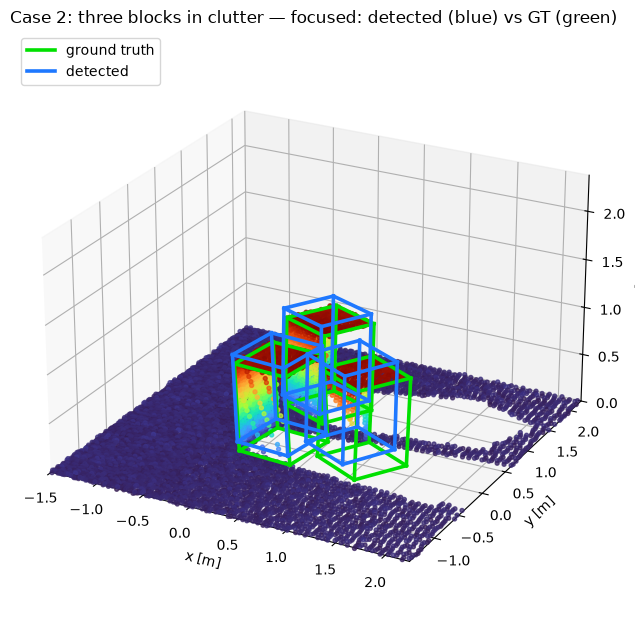

In [5]:
pts2, gt2 = random_scene(3, SHOW, np.random.default_rng(4), spacing=1.0, clutter=CLUTTER)
_ = showcase_case(pts2, gt2, "Case 2: three blocks in clutter")


### Case 3 — clutter only, no blocks (false-positive check)

The working area is empty; a robust detector must return **zero** blocks despite the
surrounding trees, container, and logs.


clutter-only scene: detected 0 block(s)  (want 0)


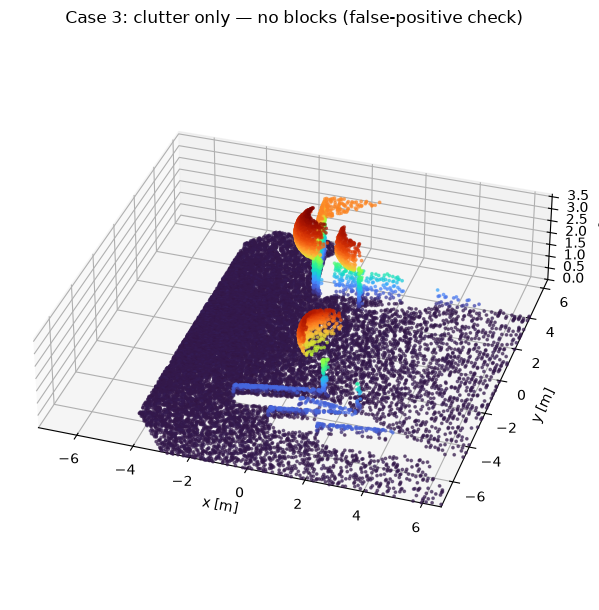

In [6]:
pts3, gt3 = generate_scene([], SHOW, np.random.default_rng(5), clutter=CLUTTER)
det3 = detect_blocks(pts3, DetectionParams())
print(f"clutter-only scene: detected {len(det3)} block(s)  (want 0)")
show_full_scene(pts3, gt=None, title="Case 3: clutter only — no blocks (false-positive check)")


## The regression gate

`tools/eval_detector.py` runs the detector over a deterministic synthetic suite and gates on
`config/detector_eval.yaml`. Isolated blocks are gated; multi-block occlusion recall is
reported as an ungated **diagnostic** (Phase-C tracking).


In [7]:
import json
import eval_detector

metrics = eval_detector.run_suite(seed=0)
print(json.dumps(metrics, indent=2))


{
  "seed": 0,
  "n_scenes": 8,
  "total_gt": 8,
  "total_detected": 8,
  "total_matched": 8,
  "recall": 1.0,
  "precision": 1.0,
  "translation_mean_m": 0.0975958479389909,
  "translation_p95_m": 0.10982611567811941,
  "rotation_mean_deg": 0.2603055525440843,
  "rotation_p95_deg": 0.37849935386964356,
  "false_positives_empty": 0,
  "diagnostics_multiblock": {
    "n_scenes": 3,
    "total_gt": 9,
    "total_detected": 5,
    "total_matched": 5,
    "recall": 0.5555555555555556,
    "precision": 1.0,
    "translation_mean_m": 0.0948927676520069,
    "translation_p95_m": 0.09904189161402793,
    "rotation_mean_deg": 0.4077850755209994,
    "rotation_p95_deg": 0.55644062969711
  }
}


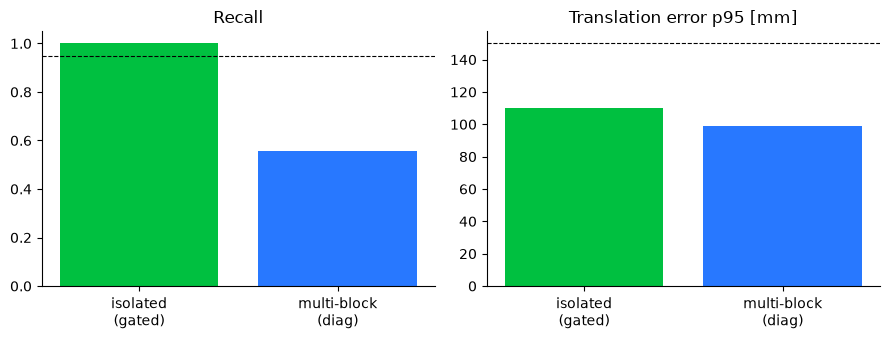

In [8]:
diag = metrics["diagnostics_multiblock"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5))
a1.bar(["isolated\n(gated)", "multi-block\n(diag)"], [metrics["recall"], diag["recall"]],
       color=["#00c040", "#2878ff"])
a1.set_ylim(0, 1.05); a1.set_title("Recall"); a1.axhline(0.95, ls="--", c="k", lw=0.8)
a2.bar(["isolated\n(gated)", "multi-block\n(diag)"],
       [metrics["translation_p95_m"]*1000, diag["translation_p95_m"]*1000],
       color=["#00c040", "#2878ff"])
a2.set_title("Translation error p95 [mm]"); a2.axhline(150, ls="--", c="k", lw=0.8)
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()


---
**Summary.** Synthetic raycasting — now with a realistic cluttered environment — gives exact
GT to develop and *gate* the detector today, while real GT is re-exported with correct
per-snapshot TF. Next up (Phase B): a gravity-initialised 6-DoF pose refine with box ICP to
drive translation error to a few cm, and a clutter-based precision gate.
